# Prédiction de la consommation énergétique des bâtiments de Seattle

**Objectif :** estimer la consommation énergétique annuelle (`SiteEnergyUse`, en kBtu) des bâtiments non résidentiels de Seattle à partir de leurs caractéristiques structurelles, sans relevé de compteur.

**Données :** *2016 Building Energy Benchmarking*, jeu public de la ville de Seattle. Placer le fichier `2016_Building_Energy_Benchmarking.csv` dans `data/raw/` avant d'exécuter le notebook.

| Étape | Contenu |
|---|---|
| 1. Analyse exploratoire | Valeurs manquantes, choix des colonnes, distributions, outliers |
| 2. Feature engineering | Surfaces en log, âge du bâtiment, sources d'énergie utilisées, tranches d'âge et de surface |
| 3. Comparaison de modèles | Dummy, régression linéaire, Random Forest, Gradient Boosting, XGBoost (validation croisée) |
| 4. Optimisation | GridSearchCV sur le Gradient Boosting, importance des variables |
| 5. Export | Sauvegarde du pipeline, ensuite servi par l'API FastAPI du dépôt |

**Résultat :** Gradient Boosting optimisé, **R² = 0,715** sur le jeu de test (cible en log).

## 1. Analyse exploratoire

### Import des modules

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import numpy as np

### Analyse Exploratoire

In [2]:
df = pd.read_csv('../data/raw/2016_Building_Energy_Benchmarking.csv')

In [3]:
# On regarde comment un batiment est défini dans ce jeu de données 
df.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,...,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,...,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,...,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [4]:
# On regarde le nombre de valeurs manquantes par colonne ainsi que leur type 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   object 
 3   PrimaryPropertyType              3376 non-null   object 
 4   PropertyName                     3376 non-null   object 
 5   Address                          3376 non-null   object 
 6   City                             3376 non-null   object 
 7   State                            3376 non-null   object 
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   object 
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   object 
 12  Latitude            

In [5]:
# le projet concerne uniquement les batiments non destinés à l'habitation
n_avant = len(df)

df = df[~df['BuildingType'].str.contains('Multifamily', na=False)].copy()

print(f"avant : {n_avant} lignes")
print(f"après : {len(df)} lignes")
print(f"supprimés : {n_avant - len(df)} bâtiments résidentiels")

avant : 3376 lignes
après : 1668 lignes
supprimés : 1708 bâtiments résidentiels


In [6]:
# types de batiments restants
df['BuildingType'].value_counts()

BuildingType
NonResidential        1460
SPS-District K-12       98
Nonresidential COS      85
Campus                  24
Nonresidential WA        1
Name: count, dtype: int64

In [7]:
# compter les valeurs manquantes par colonne
valeurs_manquantes = df.isnull().sum()
pct_manquants = (valeurs_manquantes / len(df) * 100).round(1)

# afficher seulement les colonnes avec des manquants
manquants_df = pd.DataFrame({
    'nb_manquants': valeurs_manquantes,
    'pourcentage': pct_manquants
})
manquants_df = manquants_df[manquants_df['nb_manquants'] > 0].sort_values('nb_manquants', ascending=False)
print(manquants_df)

                                 nb_manquants  pourcentage
Comments                                 1668        100.0
Outlier                                  1651         99.0
YearsENERGYSTARCertified                 1570         94.1
ThirdLargestPropertyUseTypeGFA           1315         78.8
ThirdLargestPropertyUseType              1315         78.8
SecondLargestPropertyUseType              813         48.7
SecondLargestPropertyUseTypeGFA           813         48.7
ENERGYSTARScore                           574         34.4
ZipCode                                    16          1.0
LargestPropertyUseTypeGFA                   6          0.4
LargestPropertyUseType                      6          0.4
SiteEUI(kBtu/sf)                            3          0.2
SiteEUIWN(kBtu/sf)                          3          0.2
SiteEnergyUseWN(kBtu)                       3          0.2
Electricity(kBtu)                           2          0.1
TotalGHGEmissions                           2          0

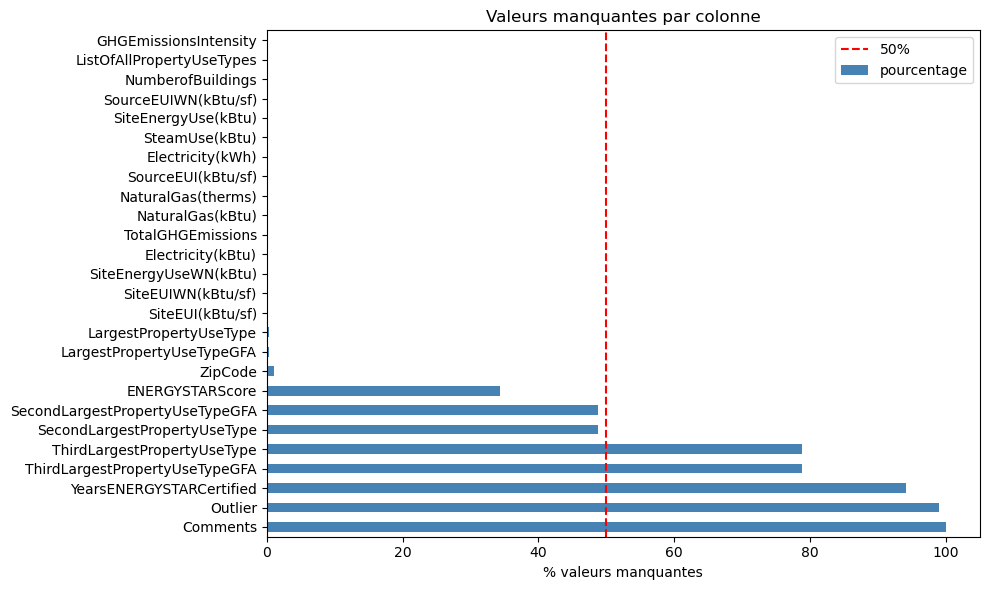

In [8]:
# graphique des valeurs manquantes
plt.figure(figsize=(10, 6))
manquants_df['pourcentage'].plot(kind='barh', color='steelblue')
plt.axvline(50, color='red', linestyle='--', label='50%')
plt.xlabel('% valeurs manquantes')
plt.title('Valeurs manquantes par colonne')
plt.legend()
plt.tight_layout()
plt.show()

**Décisions :**
- `Comments` : 100% manquant → on supprime la colonne
- `YearsENERGYSTARCertified` : ~94% manquant → on supprime
- `ThirdLargestPropertyUseType` : ~79% manquant → on supprime
- `ENERGYSTARScore` : ~51% manquant → on supprime
- `SecondLargestPropertyUseType` : ~46% manquant + peu pertinent pour l'étude → on supprime
- `ZipCode` : seulement 13 manquants → on imputera plus tard
- Pour les autres colonnes avec peu de manquants : on supprime les lignes concernées

In [9]:
# est-ce que le batiment utilise cette source d'energie oui ou non
# on ne peut pas utiliser les valeurs brutes car ca serait du data leakage
df['has_electricity'] = (df['Electricity(kBtu)'].fillna(0) > 0).astype(int)
df['has_gas'] = (df['NaturalGas(kBtu)'].fillna(0) > 0).astype(int)
df['has_steam'] = (df['SteamUse(kBtu)'].fillna(0) > 0).astype(int)

print(df[['has_electricity', 'has_gas', 'has_steam']].sum())

has_electricity    1654
has_gas            1189
has_steam           114
dtype: int64


In [10]:
colonnes_a_supprimer = [
    # identifiants, pas utiles pour predire
    'OSEBuildingID', 'DataYear', 'TaxParcelIdentificationNumber',
    'PropertyName', 'Address', 'City', 'State',
    # on garde ZipCode, on supprime lat/lon (moins pertinent selon mentor)
    'Latitude', 'Longitude',
    # trop de valeurs manquantes
    'Comments', 'YearsENERGYSTARCertified',
    'ThirdLargestPropertyUseType', 'ThirdLargestPropertyUseTypeGFA',
    'SecondLargestPropertyUseType', 'SecondLargestPropertyUseTypeGFA',
    'ENERGYSTARScore',
    # data leakage : ces colonnes sont calculées à partir de la conso qu'on veut predire
    'SiteEUI(kBtu/sf)', 'SiteEUIWN(kBtu/sf)',
    'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)',
    'SiteEnergyUseWN(kBtu)', 'GHGEmissionsIntensity',
    # valeurs brutes d'energie (remplacées par les binaires)
    'Electricity(kWh)', 'Electricity(kBtu)',
    'NaturalGas(therms)', 'NaturalGas(kBtu)',
    'SteamUse(kBtu)',
]

df.drop(columns=colonnes_a_supprimer, inplace=True)
print(f"colonnes restantes : {df.shape[1]}")
print(df.columns.tolist())

colonnes restantes : 22
['BuildingType', 'PrimaryPropertyType', 'ZipCode', 'CouncilDistrictCode', 'Neighborhood', 'YearBuilt', 'NumberofBuildings', 'NumberofFloors', 'PropertyGFATotal', 'PropertyGFAParking', 'PropertyGFABuilding(s)', 'ListOfAllPropertyUseTypes', 'LargestPropertyUseType', 'LargestPropertyUseTypeGFA', 'SiteEnergyUse(kBtu)', 'DefaultData', 'ComplianceStatus', 'Outlier', 'TotalGHGEmissions', 'has_electricity', 'has_gas', 'has_steam']


In [11]:
n0 = len(df)

# 1. supprimer les batiments signalés comme outliers par la ville
df = df[df['Outlier'].isna()].drop(columns=['Outlier'])
print(f"après suppression outliers : {len(df)} (-{n0 - len(df)})")

# 2. consommation nulle = incohérent
n1 = len(df)
df = df[df['SiteEnergyUse(kBtu)'] > 0]
print(f"après suppression conso nulle : {len(df)} (-{n1 - len(df)})")

# 3. données par défaut (estimées, pas mesurées)
n2 = len(df)
df = df[df['DefaultData'] == False].drop(columns=['DefaultData'])
print(f"après suppression DefaultData : {len(df)} (-{n2 - len(df)})")

# 4. seulement les batiments conformes
n3 = len(df)
df = df[df['ComplianceStatus'] == 'Compliant'].drop(columns=['ComplianceStatus'])
print(f"après filtre conformité : {len(df)} (-{n3 - len(df)})")

# 5. supprimer si la cible est manquante
n4 = len(df)
df.dropna(subset=['SiteEnergyUse(kBtu)', 'TotalGHGEmissions'], inplace=True)
print(f"après suppression target manquante : {len(df)} (-{n4 - len(df)})")

print(f"\nbatiments conservés : {len(df)}")

après suppression outliers : 1651 (-17)
après suppression conso nulle : 1633 (-18)
après suppression DefaultData : 1548 (-85)
après filtre conformité : 1548 (-0)
après suppression target manquante : 1548 (-0)

batiments conservés : 1548


In [12]:
df.describe()

,ZipCode,CouncilDistrictCode,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,SiteEnergyUse(kBtu),TotalGHGEmissions,has_electricity,has_gas,has_steam
count,1535.000000,1548.000000,1548.000000,1548.000000,1548.000000,1.548000e+03,1548.000000,1.548000e+03,1.544000e+03,1.548000e+03,1548.000000,1548.000000,1548.000000,1548.000000
mean,98116.776547,4.415375,1961.644057,1.178941,4.276486,1.213321e+05,13842.337209,1.074898e+05,9.994564e+04,8.860058e+06,193.608908,0.998062,0.713178,0.072997
std,18.695570,2.191527,32.886918,3.039221,6.780694,3.062944e+05,43721.822291,2.926272e+05,2.855014e+05,3.130568e+07,779.105278,0.043994,0.452424,0.260216
min,98006.000000,1.000000,1900.000000,0.000000,0.000000,1.128500e+04,0.000000,3.636000e+03,5.656000e+03,5.713320e+04,-0.800000,0.000000,0.000000,0.000000
25%,98104.000000,2.000000,1930.000000,1.000000,1.000000,2.884325e+04,0.000000,2.793675e+04,2.501575e+04,1.251083e+06,20.655000,1.000000,0.000000,0.000000
50%,98109.000000,4.000000,1965.500000,1.000000,2.000000,4.815900e+04,0.000000,4.608400e+04,4.204300e+04,2.732167e+06,49.845000,1.000000,1.000000,0.000000
75%,98125.000000,7.000000,1989.000000,1.000000,4.000000,1.076615e+05,0.000000,9.556825e+04,9.203675e+04,7.294487e+06,147.227500,1.000000,1.000000,0.000000
max,98199.000000,7.000000,2015.000000,111.000000,99.000000,9.320156e+06,512608.000000,9.320156e+06,9.320156e+06,8.739237e+08,16870.980000,1.000000,1.000000,1.000000


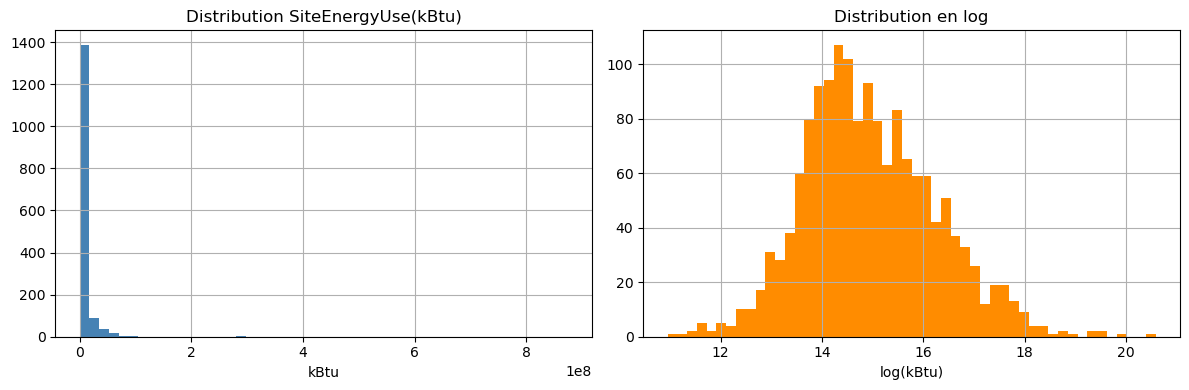

skewness : 17.48
→ distribution très asymétrique, on va travailler en log


In [13]:
# distribution de la cible - elle est très asymétrique
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['SiteEnergyUse(kBtu)'].hist(bins=50, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution SiteEnergyUse(kBtu)')
axes[0].set_xlabel('kBtu')

# version log pour mieux voir
np.log1p(df['SiteEnergyUse(kBtu)']).hist(bins=50, ax=axes[1], color='darkorange')
axes[1].set_title('Distribution en log')
axes[1].set_xlabel('log(kBtu)')

plt.tight_layout()
plt.show()

print(f"skewness : {df['SiteEnergyUse(kBtu)'].skew():.2f}")
print("→ distribution très asymétrique, on va travailler en log")

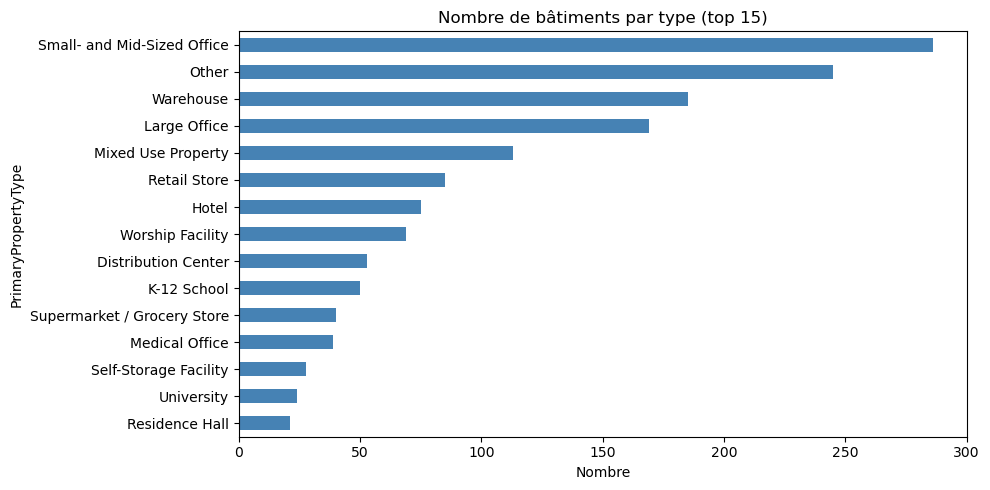

In [14]:
# combien de batiments par type
plt.figure(figsize=(10, 5))
df['PrimaryPropertyType'].value_counts().head(15).plot(kind='barh', color='steelblue')
plt.title('Nombre de bâtiments par type (top 15)')
plt.xlabel('Nombre')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

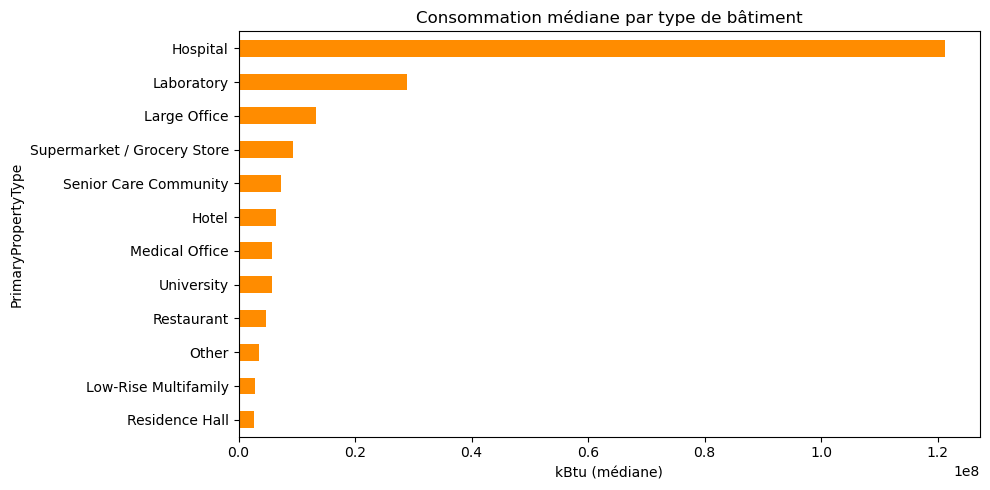

In [15]:
# consommation selon le type de batiment
plt.figure(figsize=(10, 5))
mediane_par_type = df.groupby('PrimaryPropertyType')['SiteEnergyUse(kBtu)'].median().sort_values(ascending=False).head(12)
mediane_par_type.plot(kind='barh', color='darkorange')
plt.title('Consommation médiane par type de bâtiment')
plt.xlabel('kBtu (médiane)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

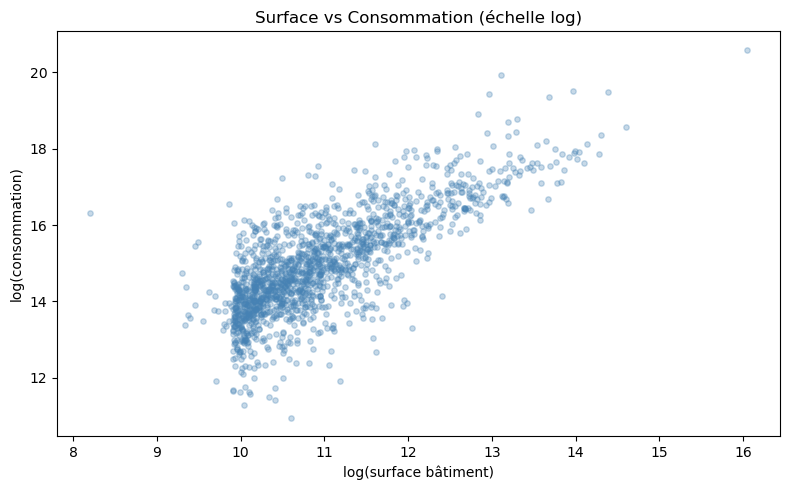

corrélation surface/conso : 0.826


In [16]:
# relation entre surface et consommation
plt.figure(figsize=(8, 5))
plt.scatter(
    np.log1p(df['PropertyGFABuilding(s)']),
    np.log1p(df['SiteEnergyUse(kBtu)']),
    alpha=0.3, s=15, color='steelblue'
)
plt.xlabel('log(surface bâtiment)')
plt.ylabel('log(consommation)')
plt.title('Surface vs Consommation (échelle log)')
plt.tight_layout()
plt.show()

print(f"corrélation surface/conso : {df['PropertyGFABuilding(s)'].corr(df['SiteEnergyUse(kBtu)']):.3f}")

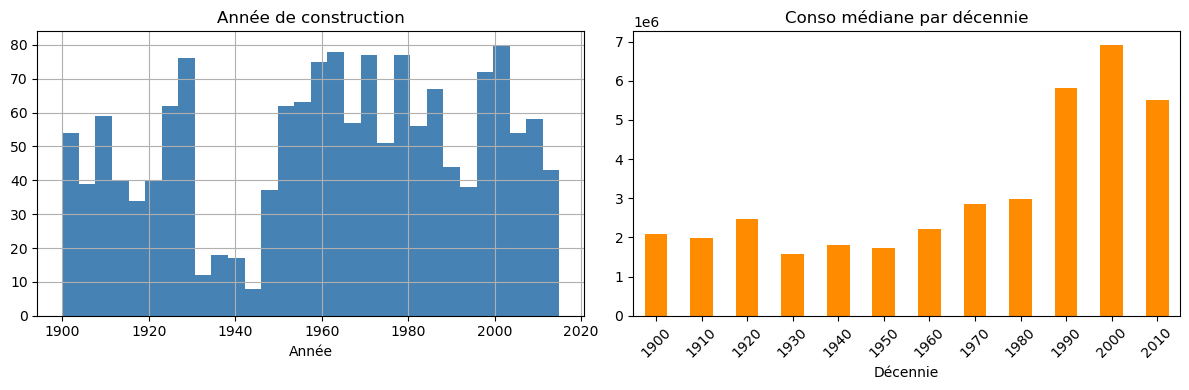

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['YearBuilt'].hist(bins=30, ax=axes[0], color='steelblue')
axes[0].set_title('Année de construction')
axes[0].set_xlabel('Année')

# consommation par décennie
df['decade'] = (df['YearBuilt'] // 10 * 10).astype(int)
df.groupby('decade')['SiteEnergyUse(kBtu)'].median().plot(
    kind='bar', ax=axes[1], color='darkorange')
axes[1].set_title('Conso médiane par décennie')
axes[1].set_xlabel('Décennie')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Nombre de codes postaux : 48
Valeurs manquantes : 13


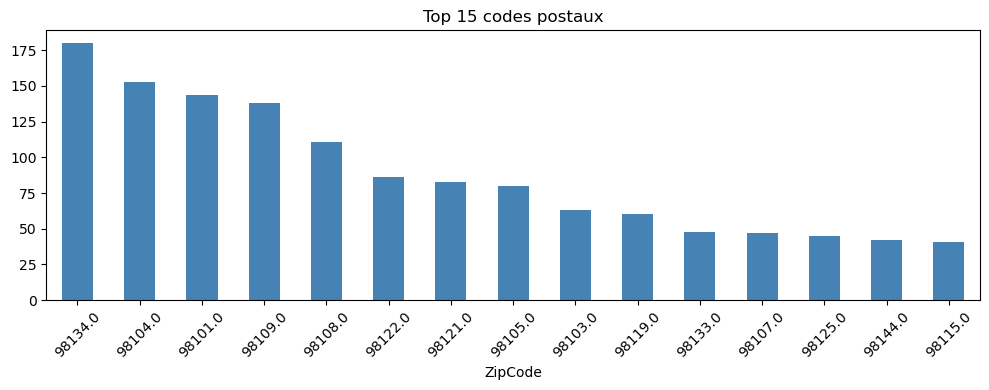

In [18]:
print(f"Nombre de codes postaux : {df['ZipCode'].nunique()}")
print(f"Valeurs manquantes : {df['ZipCode'].isna().sum()}")

# top codes postaux
plt.figure(figsize=(10, 4))
df['ZipCode'].value_counts().head(15).plot(kind='bar', color='steelblue')
plt.title('Top 15 codes postaux')
plt.xlabel('ZipCode')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

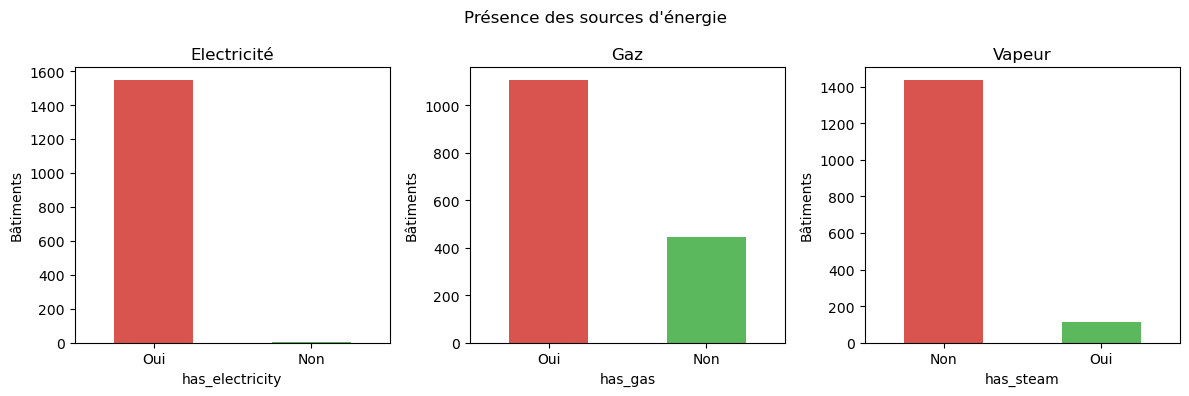

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, col, label in zip(axes,
    ['has_electricity', 'has_gas', 'has_steam'],
    ['Electricité', 'Gaz', 'Vapeur']):

    counts = df[col].value_counts().rename({0: 'Non', 1: 'Oui'})
    counts.plot(kind='bar', ax=ax, color=['#d9534f', '#5cb85c'], rot=0)
    ax.set_title(label)
    ax.set_ylabel('Bâtiments')

plt.suptitle('Présence des sources d\'énergie', fontsize=12)
plt.tight_layout()
plt.show()

# Modélisation 

### Import des modules 

In [20]:
#Selection
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV, 
    cross_validate,
)
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error 
from sklearn.inspection import permutation_importance

#Preprocess
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

#Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
import time


### Feature Engineering

In [21]:
# voir ce qui reste comme manquants
print(df.isnull().sum()[df.isnull().sum() > 0])

ZipCode                      13
LargestPropertyUseType        4
LargestPropertyUseTypeGFA     4
dtype: int64


In [22]:
# ZipCode : on remplace par le code postal le plus fréquent du même quartier
df['ZipCode'] = df.groupby('Neighborhood')['ZipCode'].transform(
    lambda x: x.fillna(x.mode()[0] if len(x.mode()) > 0 else x.median())
)
# si encore des manquants on prend la médiane globale
df['ZipCode'] = df['ZipCode'].fillna(df['ZipCode'].median())
df['ZipCode'] = df['ZipCode'].astype(int)

# NumberofBuildings : médiane
df['NumberofBuildings'] = df['NumberofBuildings'].fillna(df['NumberofBuildings'].median())

# LargestPropertyUseType : on met 'Unknown' pour les 4 manquants
df['LargestPropertyUseType'] = df['LargestPropertyUseType'].fillna('Unknown')

print("manquants restants :")
restants = df.isnull().sum()[df.isnull().sum() > 0]
print(restants if len(restants) > 0 else "aucun ✅")
print(f"\nbatiments conservés : {len(df)}")

manquants restants :
LargestPropertyUseTypeGFA    4
dtype: int64

batiments conservés : 1548


In [23]:
# age du batiment (conseil mentor : plus parlant que l'année brute)
df['building_age'] = 2016 - df['YearBuilt']
print("age min:", df['building_age'].min(), "  age max:", df['building_age'].max())

age min: 1   age max: 116


In [24]:
# nombre de sources d'energie utilisées
df['nb_sources_energie'] = df['has_electricity'] + df['has_gas'] + df['has_steam']
print(df['nb_sources_energie'].value_counts())

nb_sources_energie
2    1092
1     392
3      62
0       2
Name: count, dtype: int64


In [25]:
# ratio surface batiment / surface totale parcelle
df['ratio_surface'] = df['PropertyGFABuilding(s)'] / (df['PropertyGFATotal'] + 1)

In [26]:
# tranches d'age (pour compresser la variable)
df['tranche_age'] = pd.cut(
    df['YearBuilt'],
    bins=[1899, 1939, 1959, 1979, 1999, 2016],
    labels=['avant 1940', '1940-1959', '1960-1979', '1980-1999', '2000+']
)
print(df['tranche_age'].value_counts())

tranche_age
avant 1940    436
1960-1979     367
1980-1999     302
2000+         235
1940-1959     208
Name: count, dtype: int64


In [27]:
# tranches de surface
df['tranche_surface'] = pd.cut(
    df['PropertyGFATotal'],
    bins=[0, 25000, 100000, 300000, float('inf')],
    labels=['petit', 'moyen', 'grand', 'tres grand']
)
print(df['tranche_surface'].value_counts())

tranche_surface
moyen         894
grand         275
petit         239
tres grand    140
Name: count, dtype: int64


In [28]:
# log des surfaces (meme raison que pour la cible)
df['log_surface_totale'] = np.log1p(df['PropertyGFATotal'])
df['log_surface_batiment'] = np.log1p(df['PropertyGFABuilding(s)'])

# log de la cible
df['log_conso'] = np.log1p(df['SiteEnergyUse(kBtu)'])

print("features créées ✅")
print(df[['building_age', 'nb_sources_energie', 'ratio_surface', 'log_conso']].head())

features créées ✅
   building_age  nb_sources_energie  ratio_surface  log_conso
0            89                   3       0.999989  15.793246
1            20                   2       0.854539  15.942305
2            47                   3       0.794251  18.100297
3            90                   3       0.999984  15.731637
4            36                   2       0.646881  16.466822


In [29]:
from sklearn.preprocessing import LabelEncoder

# label encoding pour les colonnes à haute cardinalité
cols_label = ['Neighborhood', 'BuildingType', 'ZipCode']

le = LabelEncoder()
for col in cols_label:
    df[col + '_enc'] = le.fit_transform(df[col].astype(str))
    print(f"{col} : {df[col].nunique()} valeurs → label encoded")

Neighborhood : 19 valeurs → label encoded
BuildingType : 5 valeurs → label encoded
ZipCode : 48 valeurs → label encoded


In [30]:
# apercu du dataset final
print(f"taille du dataset : {df.shape}")
df.head()

taille du dataset : (1548, 31)


,BuildingType,PrimaryPropertyType,ZipCode,CouncilDistrictCode,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,...,nb_sources_energie,ratio_surface,tranche_age,tranche_surface,log_surface_totale,log_surface_batiment,log_conso,Neighborhood_enc,BuildingType_enc,ZipCode_enc
0,NonResidential,Hotel,98101,7,DOWNTOWN,1927,1.0,12,88434,0,...,3,0.999989,avant 1940,moyen,11.390023,11.390023,15.793246,6,1,7
1,NonResidential,Hotel,98101,7,DOWNTOWN,1996,1.0,11,103566,15064,...,2,0.854539,1980-1999,grand,11.547974,11.390792,15.942305,6,1,7
2,NonResidential,Hotel,98101,7,DOWNTOWN,1969,1.0,41,956110,196718,...,3,0.794251,1960-1979,tres grand,13.770629,13.540275,18.100297,6,1,7
3,NonResidential,Hotel,98101,7,DOWNTOWN,1926,1.0,10,61320,0,...,3,0.999984,avant 1940,moyen,11.023878,11.023878,15.731637,6,1,7
4,NonResidential,Hotel,98121,7,DOWNTOWN,1980,1.0,18,175580,62000,...,2,0.646881,1980-1999,grand,12.075856,11.640272,16.466822,6,1,25


### Préparation des features pour la modélisation

In [31]:
# features numériques qu'on va utiliser
features_num = [
    'log_surface_totale',
    'log_surface_batiment',
    'ratio_surface',
    'building_age',
    'NumberofFloors',
    'NumberofBuildings',
    'has_electricity',
    'has_gas',
    'has_steam',
    'nb_sources_energie',
    # label encodées
    'Neighborhood_enc',
    'BuildingType_enc',
    'ZipCode_enc',
]

# features catégorielles pour le one hot encoding (dans la pipeline)
features_cat = [
    'PrimaryPropertyType',
    'tranche_age',
    'tranche_surface',
]

TARGET = 'log_conso'

toutes_features = features_num + features_cat
df_model = df[toutes_features + [TARGET, 'SiteEnergyUse(kBtu)']].dropna(subset=[TARGET]).copy()

print(f"dataset pour modélisation : {df_model.shape}")

dataset pour modélisation : (1548, 18)


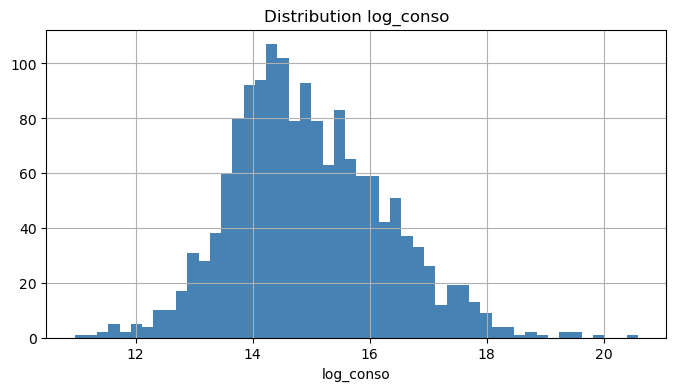

In [32]:
# on regarde la distribution
plt.figure(figsize=(8, 4))
df_model[TARGET].hist(bins=50, color='steelblue')
plt.title('Distribution log_conso')
plt.xlabel('log_conso')
plt.show()

In [33]:
# on supprime les valeurs extremes (1% de chaque côté)
# pour ne pas trop perdre de batiments on choisit des seuils larges
n_avant = len(df_model)

q01 = df_model[TARGET].quantile(0.01)
q99 = df_model[TARGET].quantile(0.99)

df_model = df_model[(df_model[TARGET] >= q01) & (df_model[TARGET] <= q99)].copy()

print(f"supprimés : {n_avant - len(df_model)} bâtiments")
print(f"conservés : {len(df_model)} bâtiments")

supprimés : 32 bâtiments
conservés : 1516 bâtiments


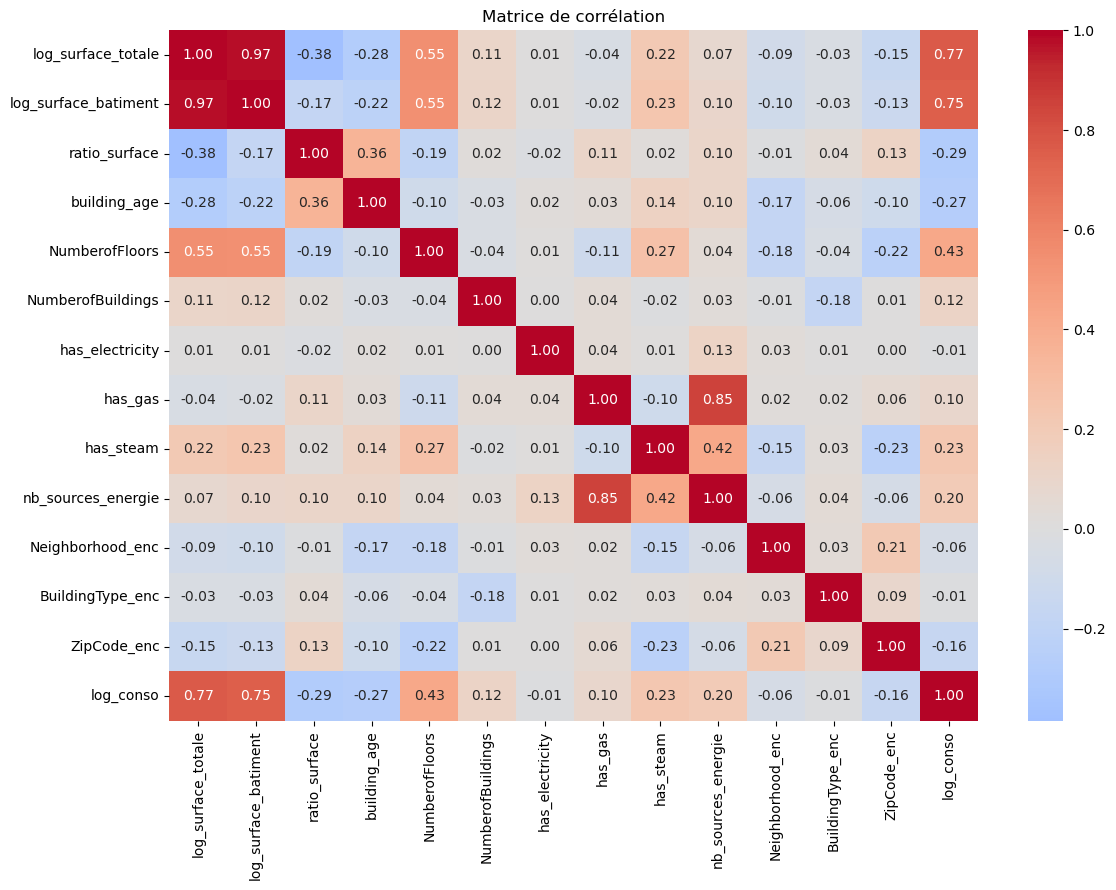

In [34]:
# corrélation entre les features numériques et la cible
corr = df_model[features_num + [TARGET]].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matrice de corrélation')
plt.tight_layout()
plt.show()

In [35]:
# features les plus corrélées à la cible
print("Corrélation avec log_conso :")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False))

Corrélation avec log_conso :
log_surface_totale      0.767036
log_surface_batiment    0.749849
NumberofFloors          0.426048
has_steam               0.227303
nb_sources_energie      0.203610
NumberofBuildings       0.121245
has_gas                 0.096247
has_electricity        -0.006145
BuildingType_enc       -0.006457
Neighborhood_enc       -0.057379
ZipCode_enc            -0.156525
building_age           -0.267004
ratio_surface          -0.285818
Name: log_conso, dtype: float64


In [36]:
RANDOM_STATE = 42

X = df_model[toutes_features]
y = df_model[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f"train : {len(X_train)} bâtiments")
print(f"test  : {len(X_test)} bâtiments")

train : 1212 bâtiments
test  : 304 bâtiments


In [37]:
# pipeline de preprocessing
# standardscaler pour normaliser les numériques
# onehotencoder pour encoder les catégorielles restantes
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), features_num),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), features_cat),
])

### Comparaison de différents modèles supervisés

In [38]:
# fonction pour tester un modèle
def tester_modele(nom, modele, X_tr, y_tr, X_te, y_te):

    pipe = Pipeline([('prep', preprocessor), ('modele', modele)])

    # validation croisée sur le train
    t0 = time.time()
    cv = cross_validate(pipe, X_tr, y_tr, cv=5,
                        scoring=['r2', 'neg_mean_absolute_error'],
                        return_train_score=True)
    duree = round(time.time() - t0, 1)

    # score final sur le test
    pipe.fit(X_tr, y_tr)
    y_pred = pipe.predict(X_te)
    r2_test = r2_score(y_te, y_pred)
    mae_test = mean_absolute_error(y_te, y_pred)

    print(f"[{nom}] R2_cv={cv['test_r2'].mean():.3f} | R2_test={r2_test:.3f} | MAE={mae_test:.3f} | {duree}s")

    return {
        'nom': nom,
        'R2 CV': round(cv['test_r2'].mean(), 3),
        'R2 CV std': round(cv['test_r2'].std(), 3),
        'R2 Train': round(cv['train_r2'].mean(), 3),
        'R2 Test': round(r2_test, 3),
        'MAE Test': round(mae_test, 3),
        '_pipe': pipe,
        '_y_pred': y_pred
    }

In [39]:
resultats = []

resultats.append(tester_modele('Dummy', DummyRegressor(strategy='median'),
    X_train, y_train, X_test, y_test))

resultats.append(tester_modele('Regression Lineaire', LinearRegression(),
    X_train, y_train, X_test, y_test))

resultats.append(tester_modele('Random Forest', RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE),
    X_train, y_train, X_test, y_test))
resultats.append(tester_modele('Gradient Boosting', GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_STATE),
    X_train, y_train, X_test, y_test))

resultats.append(tester_modele('XGBoost', XGBRegressor(n_estimators=100, random_state=RANDOM_STATE),
    X_train, y_train, X_test, y_test))

[Dummy] R2_cv=-0.014 | R2_test=-0.015 | MAE=1.002 | 0.2s
[Regression Lineaire] R2_cv=0.720 | R2_test=0.712 | MAE=0.486 | 0.2s
[Random Forest] R2_cv=0.707 | R2_test=0.688 | MAE=0.510 | 7.8s
[Gradient Boosting] R2_cv=0.725 | R2_test=0.716 | MAE=0.488 | 2.6s
[XGBoost] R2_cv=0.680 | R2_test=0.654 | MAE=0.535 | 1.0s


In [40]:
# tableau récapitulatif
df_resultats = pd.DataFrame([{k: v for k, v in r.items() if not k.startswith('_')} for r in resultats])
print(df_resultats.to_string(index=False))

                nom  R2 CV  R2 CV std  R2 Train  R2 Test  MAE Test
              Dummy -0.014      0.014    -0.011   -0.015     1.002
Regression Lineaire  0.720      0.044     0.752    0.712     0.486
      Random Forest  0.707      0.045     0.958    0.688     0.510
  Gradient Boosting  0.725      0.033     0.828    0.716     0.488
            XGBoost  0.680      0.033     0.992    0.654     0.535


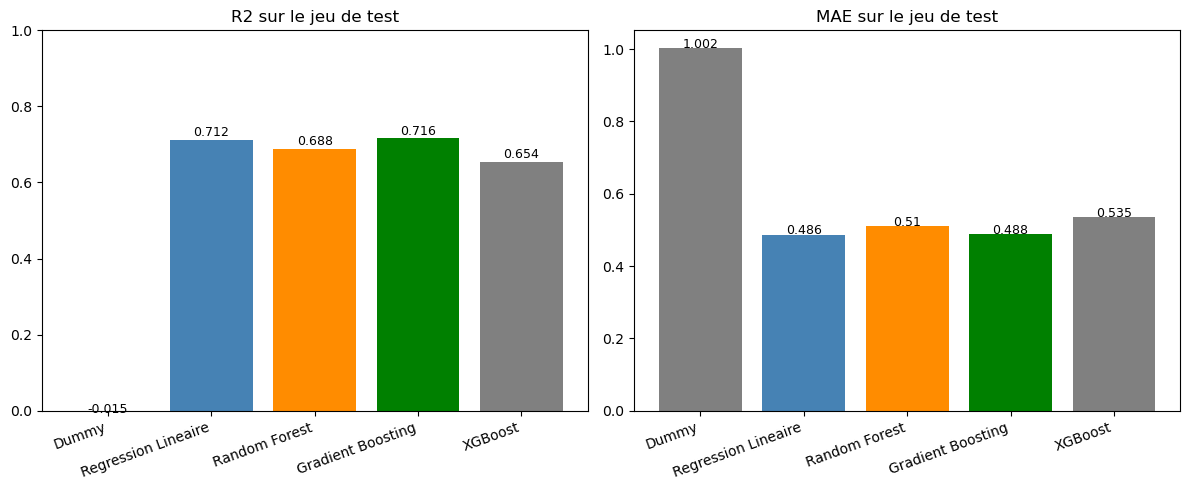

In [41]:
# graphique comparatif
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
noms = df_resultats['nom']
x = range(len(noms))
couleurs = ['gray', 'steelblue', 'darkorange', 'green']

# R2
bars = axes[0].bar(x, df_resultats['R2 Test'], color=couleurs)
axes[0].set_xticks(x)
axes[0].set_xticklabels(noms, rotation=20, ha='right')
axes[0].set_title('R2 sur le jeu de test')
axes[0].set_ylim(0, 1)
for bar, val in zip(bars, df_resultats['R2 Test']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 str(val), ha='center', fontsize=9)

# MAE
bars2 = axes[1].bar(x, df_resultats['MAE Test'], color=couleurs)
axes[1].set_xticks(x)
axes[1].set_xticklabels(noms, rotation=20, ha='right')
axes[1].set_title('MAE sur le jeu de test')
for bar, val in zip(bars2, df_resultats['MAE Test']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                 str(val), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

In [42]:
# detection overfit
for r in resultats:
    ecart = r['R2 Train'] - r['R2 CV']
    print(f"{r['nom']:<25} train={r['R2 Train']:.3f}  cv={r['R2 CV']:.3f}  ecart={ecart:+.3f}")

Dummy                     train=-0.011  cv=-0.014  ecart=+0.003
Regression Lineaire       train=0.752  cv=0.720  ecart=+0.032
Random Forest             train=0.958  cv=0.707  ecart=+0.251
Gradient Boosting         train=0.828  cv=0.725  ecart=+0.103
XGBoost                   train=0.992  cv=0.680  ecart=+0.312


### Optimisation et interprétation du modèle

In [43]:
from sklearn.model_selection import GridSearchCV

meilleure_pipe = Pipeline([
    ('prep', preprocessor),
    ('modele', GradientBoostingRegressor(random_state=RANDOM_STATE))
])

# on teste une petite grille d'abord pour vérifier que le code marche
grille_test = {
    'modele__n_estimators': [100, 200],
    'modele__max_depth': [3, 4],
    'modele__learning_rate': [0.05, 0.1],
}

gs_test = GridSearchCV(meilleure_pipe, grille_test, cv=3, scoring='r2', n_jobs=-1)
gs_test.fit(X_train, y_train)
print("petite grille ok, meilleurs params :", gs_test.best_params_)

petite grille ok, meilleurs params : {'modele__learning_rate': 0.1, 'modele__max_depth': 3, 'modele__n_estimators': 100}


In [44]:
# grille complète
grille = {
    'modele__n_estimators': [100, 200, 300],
    'modele__max_depth': [3, 4, 5],
    'modele__learning_rate': [0.05, 0.1],
    'modele__min_samples_leaf': [5, 10],
}

gs = GridSearchCV(meilleure_pipe, grille, cv=5, scoring='r2', n_jobs=-1, verbose=1)
gs.fit(X_train, y_train)

print(f"\nmeilleurs hyperparamètres : {gs.best_params_}")
print(f"R2 CV : {gs.best_score_:.4f}")

y_pred_final = gs.predict(X_test)
print(f"R2 test : {r2_score(y_test, y_pred_final):.4f}")
print(f"MAE test : {mean_absolute_error(y_test, y_pred_final):.4f}")

Fitting 5 folds for each of 36 candidates, totalling 180 fits

meilleurs hyperparamètres : {'modele__learning_rate': 0.05, 'modele__max_depth': 3, 'modele__min_samples_leaf': 5, 'modele__n_estimators': 300}
R2 CV : 0.7340
R2 test : 0.7150
MAE test : 0.4805


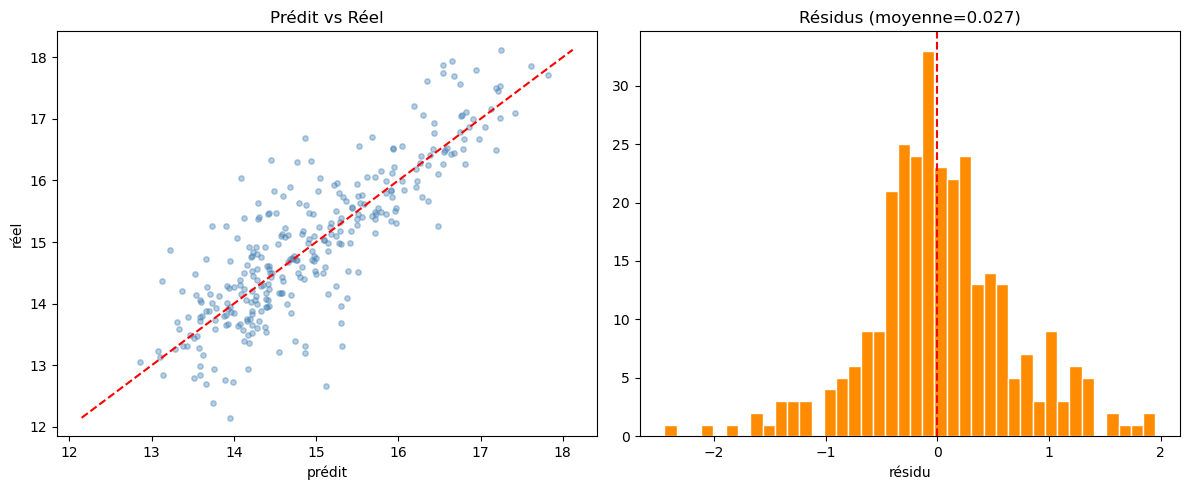

In [45]:
residus = y_test - y_pred_final

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# predit vs reel
axes[0].scatter(y_pred_final, y_test, alpha=0.4, s=15, color='steelblue')
mini = min(y_pred_final.min(), y_test.min())
maxi = max(y_pred_final.max(), y_test.max())
axes[0].plot([mini, maxi], [mini, maxi], 'r--')
axes[0].set_xlabel('prédit')
axes[0].set_ylabel('réel')
axes[0].set_title('Prédit vs Réel')

# distribution des residus
axes[1].hist(residus, bins=40, color='darkorange', edgecolor='white')
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title(f'Résidus (moyenne={residus.mean():.3f})')
axes[1].set_xlabel('résidu')

plt.tight_layout()
plt.show()

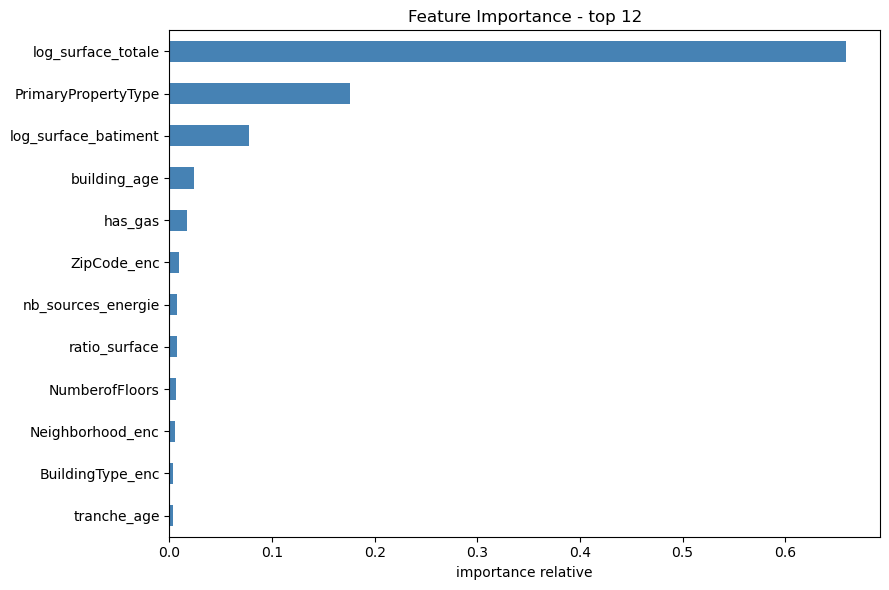

log_surface_totale      0.659450
PrimaryPropertyType     0.175742
log_surface_batiment    0.077140
building_age            0.023799
has_gas                 0.017500
ZipCode_enc             0.009549
nb_sources_energie      0.007729
ratio_surface           0.006883
NumberofFloors          0.006265
Neighborhood_enc        0.005588
dtype: float64


In [46]:
# recuperer les noms de features après le one hot encoding
noms_ohe = gs.best_estimator_.named_steps['prep'].named_transformers_['cat']     .get_feature_names_out(features_cat).tolist()

tous_noms = features_num + noms_ohe

# importances du modele
importances = gs.best_estimator_.named_steps['modele'].feature_importances_
feat_imp = pd.Series(importances, index=tous_noms).sort_values(ascending=False)

# regrouper les colonnes OHE par feature d'origine
feat_imp_groupe = feat_imp.copy()
for col in features_cat:
    cols_ohe = [f for f in feat_imp.index if f.startswith(col)]
    feat_imp_groupe[col] = feat_imp_groupe[cols_ohe].sum()
    feat_imp_groupe.drop(cols_ohe, inplace=True)

feat_imp_groupe = feat_imp_groupe.sort_values(ascending=False).head(12)

plt.figure(figsize=(9, 6))
feat_imp_groupe.plot(kind='barh', color='steelblue')
plt.gca().invert_yaxis()
plt.title('Feature Importance - top 12')
plt.xlabel('importance relative')
plt.tight_layout()
plt.show()

print(feat_imp_groupe.head(10))

In [47]:
# on a travaillé en log, on reconvertit pour interpréter
y_pred_kbtu = np.expm1(y_pred_final)
y_test_kbtu = np.expm1(y_test)

mae_kbtu = mean_absolute_error(y_test_kbtu, y_pred_kbtu)
mediane_kbtu = y_test_kbtu.median()

print(f"MAE en kBtu : {mae_kbtu:,.0f}")
print(f"Médiane cible : {mediane_kbtu:,.0f}")
print(f"Erreur relative : {mae_kbtu/mediane_kbtu:.1%}")

MAE en kBtu : 2,892,395
Médiane cible : 2,796,274
Erreur relative : 103.4%


In [48]:
from sklearn.metrics import mean_absolute_percentage_error
mape = mean_absolute_percentage_error(y_test_kbtu, y_pred_kbtu) * 100
print(f"MAPE : {mape:.1f}%")

MAPE : 56.3%


In [49]:
import joblib
import os

os.makedirs('../models', exist_ok=True)
joblib.dump(gs, '../models/model.pkl')
print("Modèle sauvegardé ✅")

Modèle sauvegardé ✅
